# calc_01. Processing the data

This notebook turns the raw model files and ERA5 into the seasonal means that the other notebooks start from. It runs on JASMIN, once per variable.

| Step | From | To |
|---|---|---|
| 1. LESFMIP to monthly stores | one netCDF file per member | `MONTHLY_DIR/<model>_<variable>_<experiment>_interp_monthly.zarr` |
| 2. ERA5 to monthly means | hourly ERA5 analyses | `SCRATCH_DIR/monthly/era5_<variable>.zarr`, on the LESFMIP grid |
| 3. Seasonal means | the monthly stores | `SCRATCH_DIR/seasonal/lesfmip_<variable>.zarr` and `SCRATCH_DIR/seasonal/era5_<variable>.zarr` |
| 4. Test sample | the monthly stores | `tests/data/*_sample.nc` in this repository |
| 5. Sea ice | (moved to notebook calc_04) | |
| 6. SAM index (once) | LEADER-EPESC's monthly SAM index of every member | `SCRATCH_DIR/seasonal/lesfmip_sam.zarr` |

**Where things are written.** Dask writes zarr stores from many workers at once, which the group workspaces do not support. So everything is written to JASMIN's scratch, to the folders in Settings (`MONTHLY_DIR`, `SCRATCH_DIR`), and the other notebooks read it from there. The last section says how to move a store to the group workspace.

Steps 1 and 2 take hours and only need running again for a new variable or new models; both skip what already exists. Every section needs the data on JASMIN, apart from section 3, which can also run on the small sample in `tests/data`: a quick way to see what each step does.

Each step shows what it made, with a **quick look** (a plain xarray plot, all its code here) before each method figure. Names end in their type: `_tree` (DataTree), `_ds` (Dataset), `_da` (DataArray), `_arr` (numpy array), `_df` (DataFrame).

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import shutil
import warnings
from importlib import reload
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import xarray as xr

from dask.distributed import wait
from plotting_modules import formatting
from extant import config, preprocessing as pp
from extant.logger import setup_logging
from extant.plots import antarctica, charts, forced_response as fr, methods

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

from importlib.util import find_spec

from extant import convert, datatree, sam, sea_ice
from extant.plots import sea_ice as sip

#(t): flox speeds up groupby/resample on dask (the seasonal means); xarray uses it automatically when installed
if find_spec('flox') is None:
    logger.warning('flox is not installed: pip install flox to speed up the seasonal means')

In [2]:
%matplotlib inline

## Settings

`VARIABLE` is the CMIP name of the variable to process. Its units, and how to convert them, are in `config.VARIABLES`: temperature goes from K to °C, $T_{°C} = T_K - 273.15$, and precipitation from kg m⁻² s⁻¹ to mm day⁻¹, $P_{mm\,day^{-1}} = 86400\,P_{kg\,m^{-2}\,s^{-1}}$.

In [180]:
OVERRIDE_SAVES = True

In [3]:
VARIABLE = config.VARIABLES['tas']
VARIABLE

Variable(name='tas', long_name='Near-surface air temperature', units='°C', scale=1.0, offset=-273.15, era5_code='2t', era5_name='t2m', table='Amon')

In [4]:
#(t): Where the raw files are read from: the LESFMIP files of VARIABLE.name (/<experiment>/<model>/*.nc, one file per
#(t): member; VARIABLE.table is its CMIP table, e.g. Amon), the hourly ERA5 analyses
#(t): (/<year>/<month>/<day>/*.<code>.nc), and
#(t): LEADER-EPESC's monthly SAM index (section 6)
RAW_DIR = Path('/gws/ssde/j25b/leader_epesc/CMIP6_SinglForcHistSimul/InterpolatedFlds') / VARIABLE.table / VARIABLE.name
ERA5_RAW_DIR = Path('/badc/ecmwf-era5/data/oper/an_sfc')
SAM_RAW_DIR = Path('/gws/ssde/j25b/leader_epesc/wg1/monthly/NAM_SAM_new_update_LastVersion_UseThese/SAM_zonal_new_jasmin')
RAW_DIR, ERA5_RAW_DIR, SAM_RAW_DIR

(PosixPath('/gws/ssde/j25b/leader_epesc/CMIP6_SinglForcHistSimul/InterpolatedFlds/Amon/tas'),
 PosixPath('/badc/ecmwf-era5/data/oper/an_sfc'),
 PosixPath('/gws/ssde/j25b/leader_epesc/wg1/monthly/NAM_SAM_new_update_LastVersion_UseThese/SAM_zonal_new_jasmin'))

In [5]:
#(t): Where everything is written, on JASMIN's scratch: the monthly LESFMIP stores (every variable's in one folder), and
#(t): this project's folder, for the ERA5 monthly means and the seasonal means
MONTHLY_DIR = Path('/work/scratch-pw4/aborow/LESFMIP/monthly_v2')
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
MONTHLY_DIR, SCRATCH_DIR

(PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2'),
 PosixPath('/work/scratch-pw4/aborow/ExtAnt'))

In [6]:
#(t): The sample in this repository (section 3's sample data, and section 4 writes it)
SAMPLE_DIR = Path('../tests/data')
SAMPLE_DIR

PosixPath('../tests/data')

## Dask Cluster

The heavy steps run on a Dask Gateway cluster on JASMIN. `jasmin.stop_all(gateway)` stops every cluster left over from an earlier kernel.

In [7]:
#(t): Start a Dask Gateway cluster, or reuse the one already running, and send it the extant package
#(c): Re-run upload_package after editing anything in extant/: the workers run its functions
from extant import jasmin

gateway, cluster, client = jasmin.connect(n_workers=20, wait_for=6)
jasmin.upload_package(client)
client

Connection method: Cluster object,Cluster type: dask_gateway.GatewayCluster
Dashboard: /_jasmin/proxy/dask-gateway/clusters/5e7a7a016911447497ff6fc035ce801f/status,


## 1. LESFMIP Files to Monthly Stores

The raw files are laid out as `<variable>/<experiment>/<model>/*.nc`, one file per member. Each model's members for one experiment are opened together and stacked along a new `member` dimension, labelled from the file names (`r1i1p1f1` and the like; `convert.member_from_path`). Only the area south of 40°S is kept.

First, which models have which experiments. Only models with at least `config.MIN_EXPERIMENTS` of the experiments are converted.

### File lists

In [181]:
#(t): The model folders in each experiment's folder of RAW_DIR
raw_model_lists = {experiment: sorted(path.name for path in (RAW_DIR / experiment).iterdir() if path.is_dir())
                   for experiment in config.MAIN_EXPERIMENTS}

In [182]:
#(t): Which models have raw files for which experiment (True/False)
availability_df = pd.DataFrame({experiment: pd.Series(True, index=models)
                                for experiment, models in raw_model_lists.items()}).notna()

In [183]:
#(t): The best-covered models first, with the number of experiments each has
availability_df = availability_df.loc[availability_df.sum(axis=1).sort_values(ascending=False, kind='stable').index]
availability_df.assign(total=availability_df.sum(axis=1))

,hist-nat,hist-aer,hist-totalO3,hist-GHG,historical,total
CanESM5,True,True,True,True,True,5
GISS-E2-1-G,True,True,True,True,True,5
HadGEM3-GC31-LL,True,True,True,True,True,5
MIROC6,True,True,True,True,True,5
MPI-ESM1-2-LR,True,True,True,True,True,5
NorESM2-LM,True,True,True,True,True,5
ACCESS-ESM1-5,True,True,False,True,True,4
BCC-CSM2-MR,True,True,False,True,True,4
CESM2,True,True,False,True,True,4
CNRM-CM6-1,True,True,False,True,True,4


In [223]:
convert_models = list(availability_df.index[availability_df.sum(axis=1) >= 5])
convert_models

['CanESM5',
 'GISS-E2-1-G',
 'HadGEM3-GC31-LL',
 'MIROC6',
 'MPI-ESM1-2-LR',
 'NorESM2-LM']

The stores left to make: each model and experiment with raw files and no store yet in `MONTHLY_DIR`. Only the `config.GROUP` files are converted (`*_interp.nc`, the files on the common 2.5° grid). To make a store again, delete it first.

In [224]:
#(t): The stores left: <model>_<variable>_<experiment>_<group>_monthly.zarr in MONTHLY_DIR, for each model and experiment
#(t): with raw files and no store yet. Todo will be all if OVERRIDE_SAVES == True
todo = [(model, experiment) for model in convert_models for experiment in config.MAIN_EXPERIMENTS
        if availability_df.loc[model, experiment]
        and (not (MONTHLY_DIR / f'{model}_{VARIABLE.name}_{experiment}_{config.GROUP}_monthly.zarr').exists() or OVERRIDE_SAVES)
       ]
todo

[('CanESM5', 'hist-nat'),
 ('CanESM5', 'hist-aer'),
 ('CanESM5', 'hist-totalO3'),
 ('CanESM5', 'hist-GHG'),
 ('CanESM5', 'historical'),
 ('GISS-E2-1-G', 'hist-nat'),
 ('GISS-E2-1-G', 'hist-aer'),
 ('GISS-E2-1-G', 'hist-totalO3'),
 ('GISS-E2-1-G', 'hist-GHG'),
 ('GISS-E2-1-G', 'historical'),
 ('HadGEM3-GC31-LL', 'hist-nat'),
 ('HadGEM3-GC31-LL', 'hist-aer'),
 ('HadGEM3-GC31-LL', 'hist-totalO3'),
 ('HadGEM3-GC31-LL', 'hist-GHG'),
 ('HadGEM3-GC31-LL', 'historical'),
 ('MIROC6', 'hist-nat'),
 ('MIROC6', 'hist-aer'),
 ('MIROC6', 'hist-totalO3'),
 ('MIROC6', 'hist-GHG'),
 ('MIROC6', 'historical'),
 ('MPI-ESM1-2-LR', 'hist-nat'),
 ('MPI-ESM1-2-LR', 'hist-aer'),
 ('MPI-ESM1-2-LR', 'hist-totalO3'),
 ('MPI-ESM1-2-LR', 'hist-GHG'),
 ('MPI-ESM1-2-LR', 'historical'),
 ('NorESM2-LM', 'hist-nat'),
 ('NorESM2-LM', 'hist-aer'),
 ('NorESM2-LM', 'hist-totalO3'),
 ('NorESM2-LM', 'hist-GHG'),
 ('NorESM2-LM', 'historical')]

### One store walk through

The first store left: its files, one member's file before and after `convert.preprocess_member`, then all the members opened together. Nothing is saved here.

In [20]:
#(t): Its member files (the config.GROUP ones, *_interp.nc), one per member
model, experiment = todo[0]
# model, experiment = ('GISS-E2-1-G', 'historical')
member_paths = sorted((RAW_DIR / experiment / model).rglob(f'*_{config.GROUP}.nc'))
member_paths

[PosixPath('/gws/ssde/j25b/leader_epesc/CMIP6_SinglForcHistSimul/InterpolatedFlds/Amon/tas/historical/GISS-E2-1-G/tas_mon_historical_GISS-E2-1-G_r10i1p1f1_interp.nc'),
 PosixPath('/gws/ssde/j25b/leader_epesc/CMIP6_SinglForcHistSimul/InterpolatedFlds/Amon/tas/historical/GISS-E2-1-G/tas_mon_historical_GISS-E2-1-G_r10i1p1f2_interp.nc'),
 PosixPath('/gws/ssde/j25b/leader_epesc/CMIP6_SinglForcHistSimul/InterpolatedFlds/Amon/tas/historical/GISS-E2-1-G/tas_mon_historical_GISS-E2-1-G_r10i1p3f1_interp.nc'),
 PosixPath('/gws/ssde/j25b/leader_epesc/CMIP6_SinglForcHistSimul/InterpolatedFlds/Amon/tas/historical/GISS-E2-1-G/tas_mon_historical_GISS-E2-1-G_r10i1p5f1_interp.nc'),
 PosixPath('/gws/ssde/j25b/leader_epesc/CMIP6_SinglForcHistSimul/InterpolatedFlds/Amon/tas/historical/GISS-E2-1-G/tas_mon_historical_GISS-E2-1-G_r11i1p1f2_interp.nc'),
 PosixPath('/gws/ssde/j25b/leader_epesc/CMIP6_SinglForcHistSimul/InterpolatedFlds/Amon/tas/historical/GISS-E2-1-G/tas_mon_historical_GISS-E2-1-G_r11i1p3f1_inter

In [29]:
#(t): The member label read from each file's name
np.array([convert.member_from_path(file) for file in member_paths])

array(['r10i1p1f1', 'r10i1p1f2', 'r10i1p3f1', 'r10i1p5f1', 'r11i1p1f2',
       'r11i1p3f1', 'r12i1p1f2', 'r12i1p3f1', 'r13i1p1f2', 'r13i1p3f1',
       'r14i1p1f2', 'r14i1p3f1', 'r15i1p1f2', 'r15i1p3f1', 'r16i1p1f2',
       'r16i1p3f1', 'r17i1p1f2', 'r17i1p3f1', 'r18i1p1f2', 'r18i1p3f1',
       'r19i1p1f2', 'r19i1p3f1', 'r1i1p1f1', 'r1i1p1f2', 'r1i1p1f3',
       'r1i1p1f5', 'r1i1p3f1', 'r1i1p5f1', 'r20i1p1f2', 'r20i1p3f1',
       'r2i1p1f1', 'r2i1p1f2', 'r2i1p1f3', 'r2i1p3f1', 'r2i1p5f1',
       'r3i1p1f1', 'r3i1p1f2', 'r3i1p1f3', 'r3i1p3f1', 'r3i1p5f1',
       'r4i1p1f1', 'r4i1p1f2', 'r4i1p1f3', 'r4i1p3f1', 'r4i1p5f1',
       'r5i1p1f1', 'r5i1p1f2', 'r5i1p1f3', 'r5i1p3f1', 'r6i1p1f1',
       'r6i1p1f2', 'r6i1p3f1', 'r6i1p5f1', 'r7i1p1f1', 'r7i1p1f2',
       'r7i1p3f1', 'r7i1p5f1', 'r8i1p1f1', 'r8i1p1f2', 'r8i1p3f1',
       'r8i1p5f1', 'r9i1p1f1', 'r9i1p1f2', 'r9i1p3f1', 'r9i1p5f1'],
      dtype='<U9')

In [22]:
#(t): One member's file as it is on disk
member_ds = xr.open_dataset(member_paths[0])

In [71]:
%%time
#(t): All the members, stacked along member (lazily)
members_ds = convert.open_members(member_paths, VARIABLE.name)

CPU times: user 518 ms, sys: 70.5 ms, total: 589 ms
Wall time: 839 ms


AlignmentError: cannot align objects with join='override' with matching indexes along dimension 'time' that don't have the same size

In [ ]:
members_ds

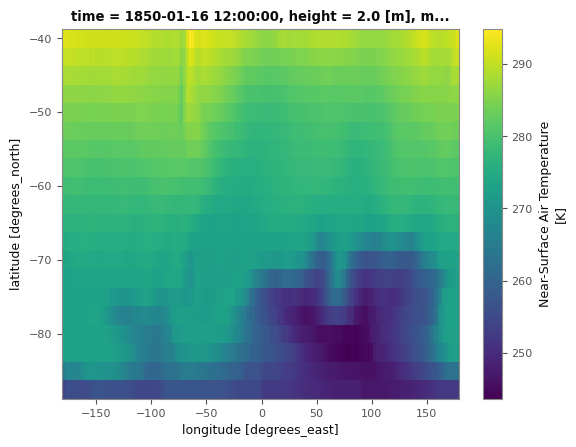

In [18]:
members_ds[VARIABLE.name].isel(member=0, time=0).plot();

### Fixing broken models (GISS-E2-1-G - historical, NoESM2-LM historical)

Some members are returning just all zeros, and some members seem to have less time stamps

In [215]:
# model, experiment = 'NorESM2-LM','historical'
# model, experiment = 'ACCESS-ESM1-5', 'hist-GHG'
# model, experiment = 'GISS-E2-1-G','historical'
# model, experiment = 'CESM2', 'hist-GHG'
model, experiment =  ('E3SM-2-1', 'hist-GHG')

In [216]:
member_paths = np.array(sorted((RAW_DIR / experiment / model).rglob(f'*_{config.GROUP}.nc')))
member_paths.shape

(10,)

In [217]:
import re

In [218]:
import cftime

time_rows = []
for path in member_paths:
    with xr.open_dataset(path, decode_times=False) as ds:
        time_da = ds['time']
        first_last = cftime.num2date(time_da.values[[0, -1]], time_da.attrs['units'], time_da.attrs.get('calendar', 'standard'))
        time_rows.append(dict(member=re.search(r"r\d+i\d+p\d+f\d+", str(path)).group(), file=path.name, n_time=ds.sizes['time'],
                              units=time_da.attrs['units'], calendar=time_da.attrs.get('calendar'),
                              first=first_last[0], last=first_last[1]))
time_df = pd.DataFrame(time_rows).set_index('member')
time_df

,file,n_time,units,calendar,first,last
member,,,,,,
r10i1p1f1,tas_mon_hist-GHG_E3SM-2-1_r10i1p1f1_interp.nc,2052,days since 1850-01-01 00:00:00,365_day,1850-01-16 12:00:00,2020-12-16 12:00:00
r11i1p1f1,tas_mon_hist-GHG_E3SM-2-1_r11i1p1f1_interp.nc,62062,days since 1850-01-01 00:00:00,365_day,1850-01-01 12:00:00,2020-12-16 12:00:00
r12i1p1f1,tas_mon_hist-GHG_E3SM-2-1_r12i1p1f1_interp.nc,2052,days since 1850-01-01 00:00:00,365_day,1850-01-16 12:00:00,2020-12-16 12:00:00
r13i1p1f1,tas_mon_hist-GHG_E3SM-2-1_r13i1p1f1_interp.nc,2052,days since 1850-01-01 00:00:00,365_day,1850-01-16 12:00:00,2020-12-16 12:00:00
r14i1p1f1,tas_mon_hist-GHG_E3SM-2-1_r14i1p1f1_interp.nc,2052,days since 1850-01-01 00:00:00,365_day,1850-01-16 12:00:00,2020-12-16 12:00:00
r15i1p1f1,tas_mon_hist-GHG_E3SM-2-1_r15i1p1f1_interp.nc,2052,days since 1850-01-01 00:00:00,365_day,1850-01-16 12:00:00,2020-12-16 12:00:00
r6i1p1f1,tas_mon_hist-GHG_E3SM-2-1_r6i1p1f1_interp.nc,2052,days since 1850-01-01 00:00:00,365_day,1850-01-16 12:00:00,2020-12-16 12:00:00
r7i1p1f1,tas_mon_hist-GHG_E3SM-2-1_r7i1p1f1_interp.nc,2052,days since 1850-01-01 00:00:00,365_day,1850-01-16 12:00:00,2020-12-16 12:00:00
r8i1p1f1,tas_mon_hist-GHG_E3SM-2-1_r8i1p1f1_interp.nc,2052,days since 1850-01-01 00:00:00,365_day,1850-01-16 12:00:00,2020-12-16 12:00:00


In [222]:
np.unique(time_df.n_time, return_counts=True)

(array([ 2052, 62062]), array([9, 1]))

In [166]:
corrupted_members = time_df[time_df.n_time < 1980]
corrupted_members.file.values

array([], dtype=object)

In [167]:
corrupted_members_giss_historical = ['tas_mon_historical_GISS-E2-1-G_r1i1p1f5_interp.nc',
       'tas_mon_historical_GISS-E2-1-G_r7i1p3f1_interp.nc']

### All models and protocals

Every store left, one after the other. If one fails, the loop stops with its error.

In [134]:
# Override to see what is going on with 'GISS-E2-1-G', 'historical'
# todo = [(model, experiment)]
# todo = todo[9:11]
# todo

[('GISS-E2-1-G', 'historical'), ('HadGEM3-GC31-LL', 'hist-nat')]

In [158]:
import os

In [208]:
LONGER_MEMBERS = {('NorESM2-LM', 'historical'), ('ACCESS-ESM1-5', 'hist-GHG'), ('CESM2', 'hist-GHG')}

In [212]:
todo[40:]

[('CESM2', 'hist-GHG'),
 ('CESM2', 'historical'),
 ('CNRM-CM6-1', 'hist-nat'),
 ('CNRM-CM6-1', 'hist-aer'),
 ('CNRM-CM6-1', 'hist-GHG'),
 ('CNRM-CM6-1', 'historical'),
 ('E3SM-2-0', 'hist-nat'),
 ('E3SM-2-0', 'hist-aer'),
 ('E3SM-2-0', 'hist-GHG'),
 ('E3SM-2-0', 'historical'),
 ('E3SM-2-1', 'hist-aer'),
 ('E3SM-2-1', 'hist-totalO3'),
 ('E3SM-2-1', 'hist-GHG'),
 ('E3SM-2-1', 'historical'),
 ('FGOALS-g3', 'hist-nat'),
 ('FGOALS-g3', 'hist-aer'),
 ('FGOALS-g3', 'hist-GHG'),
 ('FGOALS-g3', 'historical'),
 ('IPSL-CM6A-LR', 'hist-nat'),
 ('IPSL-CM6A-LR', 'hist-aer'),
 ('IPSL-CM6A-LR', 'hist-GHG'),
 ('IPSL-CM6A-LR', 'historical'),
 ('MRI-ESM2-0', 'hist-nat'),
 ('MRI-ESM2-0', 'hist-aer'),
 ('MRI-ESM2-0', 'hist-GHG'),
 ('MRI-ESM2-0', 'historical')]

In [214]:
%%time
#(t): Every store left, one after the other, each saved as soon as it is made. Written as <store>.part and renamed once
#(t): complete, so a crash never leaves half a store under the real name (the stores left are worked out from the names).
#(t): drop_encoding: the netCDF files' own settings (compression, chunk sizes) are not zarr's
count = 0
for model, experiment in todo[40:]:
    store_path = MONTHLY_DIR / f'{model}_{VARIABLE.name}_{experiment}_{config.GROUP}_monthly.zarr'
    store_part_path = store_path.with_name(store_path.name + '.part')
    logger.info(f'{count}:{model} {experiment}: writing {store_path}')
    member_paths = sorted((RAW_DIR / experiment / model).rglob(f'*_{config.GROUP}.nc'))
    if model == 'GISS-E2-1-G' and experiment == 'historical':
        member_paths = [mp for mp in member_paths if str(mp).split('/')[-1] not in ccorrupted_members_giss_historical]
    # NorESM2-LM has many ensemble members that are too long. Don't want to thwo away, just do an 'inner' join
    open_kwargs = {**convert.OPEN_KWARGS, 'join': 'inner'} if (model, experiment) in LONGER_MEMBERS else None
    # print(open_kwargs)

    members_ds = convert.open_members(member_paths, VARIABLE.name, open_kwargs)
    members_ds.drop_encoding().to_zarr(store_part_path, mode='w', consolidated=True)
    if OVERRIDE_SAVES and os.path.exists(store_path): shutil.rmtree(store_path)
    store_part_path.rename(store_path)
    logger.info(f'{model} {experiment}: saved')
    count+=1

14:59:30 INFO    extant | 0:CESM2 hist-GHG: writing /work/scratch-pw4/aborow/LESFMIP/monthly_v2/CESM2_tas_hist-GHG_interp_monthly.zarr
15:00:05 INFO    extant | CESM2 hist-GHG: saved
15:00:05 INFO    extant | 1:CESM2 historical: writing /work/scratch-pw4/aborow/LESFMIP/monthly_v2/CESM2_tas_historical_interp_monthly.zarr
15:00:41 INFO    extant | CESM2 historical: saved
15:00:41 INFO    extant | 2:CNRM-CM6-1 hist-nat: writing /work/scratch-pw4/aborow/LESFMIP/monthly_v2/CNRM-CM6-1_tas_hist-nat_interp_monthly.zarr
15:01:02 INFO    extant | CNRM-CM6-1 hist-nat: saved
15:01:02 INFO    extant | 3:CNRM-CM6-1 hist-aer: writing /work/scratch-pw4/aborow/LESFMIP/monthly_v2/CNRM-CM6-1_tas_hist-aer_interp_monthly.zarr
15:01:14 INFO    extant | CNRM-CM6-1 hist-aer: saved
15:01:14 INFO    extant | 4:CNRM-CM6-1 hist-GHG: writing /work/scratch-pw4/aborow/LESFMIP/monthly_v2/CNRM-CM6-1_tas_hist-GHG_interp_monthly.zarr
15:01:16 INFO    extant | CNRM-CM6-1 hist-GHG: saved
15:01:16 INFO    extant | 5:CNRM-C

AlignmentError: cannot align objects with join='override' with matching indexes along dimension 'time' that don't have the same size

In [ ]:
# members_ds.tas.isel(time=0).plot(col='member', col_wrap=6)

In [ ]:
members_ds.tas.isel(lat=0, lon=0).plot(hue='member', add_legend=False);

A store that fails can be saved by hand without its broken files, then the loop re-run. For example, member 55 of historical GISS-E2-1-G has no time axis:

```python
member_paths = sorted((RAW_DIR / 'historical' / 'GISS-E2-1-G').rglob(f'*_{config.GROUP}.nc'))
member_paths.pop(55)
members_ds = convert.open_members(member_paths, VARIABLE)
store_path = MONTHLY_DIR / f'GISS-E2-1-G_{VARIABLE}_historical_{config.GROUP}_monthly.zarr'
members_ds.drop_encoding().to_zarr(store_path, mode='w', consolidated=True)
```

## 2. ERA5 Hourly Files to Monthly Means

Each month of hourly analyses is averaged on a worker (summing in float64), then regridded **conservatively** onto the LESFMIP 2.5° grid with xesmf, so each model grid cell gets the area-weighted mean of the ERA5 cells inside it. Each year is saved as its own store as soon as its twelve months are done, so an interrupted run picks up where it stopped. At the end the year stores are joined into one store, checked, and deleted.

ERA5 is kept on its own (standard) calendar. Its seasons are matched to the models' by their (year, season) labels in step 3, not by date.

In [10]:
#(t): Where each year's store goes while the years are worked out, and the store they are joined into
era5_years_dir = SCRATCH_DIR / 'monthly' / f'era5_{VARIABLE.name}_years'
era5_monthly_path = SCRATCH_DIR / 'monthly' / f'era5_{VARIABLE.name}.zarr'
era5_years_dir, era5_monthly_path

21:36:46 INFO    extant.storage | opening /work/scratch-pw4/aborow/ExtAnt/monthly/era5_tas.zarr


[1979,
 1980,
 1981,
 1982,
 1983,
 1984,
 1985,
 1986,
 1987,
 1988,
 1989,
 1990,
 1991,
 1992,
 1993,
 1994,
 1995,
 1996,
 1997,
 1998,
 1999,
 2000,
 2001,
 2002,
 2003,
 2004,
 2005,
 2006,
 2007,
 2008,
 2009,
 2010,
 2011,
 2012,
 2013,
 2014,
 2015,
 2016,
 2017,
 2018,
 2019,
 2020,
 2021,
 2022,
 2023,
 2024]

In [ ]:
#(t): Years already done: saved as a year store (an interrupted run), or in the joined store
done_years = [int(path.stem) for path in sorted(era5_years_dir.glob('*.zarr'))]
if era5_monthly_path.exists():
    done_years += np.unique(xr.open_zarr(era5_monthly_path)['time'].dt.year).tolist()
done_years

In [11]:
todo_years = [year for year in range(config.ERA5_START_YEAR, 2025) if year not in done_years]
todo_years

[]

### Grid to regrid onto

One LESFMIP monthly store: they are all on the same 2.5° grid.

In [12]:
#(t): CanESM5's historical store
target_path = MONTHLY_DIR / f'CanESM5_{VARIABLE.name}_historical_{config.GROUP}_monthly.zarr'
target_path

21:36:46 INFO    extant.storage | opening /work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_historical_interp_monthly.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/codecs/vlen_utf8.py:44: UserWarning: The codec `vlen-utf8` is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  return cls(**configuration_parsed)


<xarray.Dataset> Size: 3GB
Dimensions:  (member: 65, time: 1980, lat: 20, lon: 144)
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * time     (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
    height   float64 8B ...
Data variables:
    tas      (member, time, lat, lon) float64 3GB dask.array<chunksize=(5, 1980, 10, 144), meta=np.ndarray>

In [ ]:
target_ds = xr.open_zarr(target_path)

### One month, step by step

January of the first year left. Each hourly file is sorted south to north and cut at `convert.ERA5_LAT_MAX` (38°S), a little north of the LESFMIP edge, so the edge cells are fully covered.

In [13]:
#(t): January's hourly files of the first year left: /<year>/<month>/<day>/*.<code>.nc (VARIABLE.era5_code)
example_files = sorted(ERA5_RAW_DIR.glob(f'{todo_years[0]}/01/*/*.{VARIABLE.era5_code}.nc'))
len(example_files), example_files[0]

IndexError: list index out of range

In [ ]:
#(t): One hour, as the worker reads it
hour_ds = convert.era5_south(xr.open_dataset(example_files[0]))

The regridder needs the edges of every cell. They go half-way between the cell centres, clipped at ±90°: the LESFMIP row at 90°S would otherwise reach 91.25°S, past the pole.

In [ ]:
import cf_xarray  # noqa: F401  (adds .cf)
import xesmf

era5_grid_ds = hour_ds[['latitude', 'longitude']].rename(latitude='lat', longitude='lon').cf.add_bounds(['lat', 'lon'])
era5_grid_ds['lat_bounds'] = era5_grid_ds['lat_bounds'].clip(-90, 90)

In [ ]:
target_grid_ds = target_ds[['lat', 'lon']].cf.add_bounds(['lat', 'lon'])
target_grid_ds['lat_bounds'] = target_grid_ds['lat_bounds'].clip(-90, 90)

In [ ]:
%%time
regridder = xesmf.Regridder(era5_grid_ds, target_grid_ds, 'conservative', periodic=True)
regridder

In [ ]:
%%time
#(t): The month's mean, worked out on a worker
month_da = xr.DataArray(client.submit(convert.era5_month_mean, example_files, VARIABLE.era5_name).result(),
                        coords=[('lat', era5_grid_ds.lat.values), ('lon', era5_grid_ds.lon.values)])

In [ ]:
month_regridded_da = regridder(month_da)
month_regridded_da

In [ ]:
#(t): Before and after, on one colour scale
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
month_da.plot(ax=axes[0], vmin=float(month_da.min()), vmax=float(month_da.max()))
month_regridded_da.plot(ax=axes[1], vmin=float(month_da.min()), vmax=float(month_da.max()));

In [ ]:
#(t): The zonal means before and after
month_da.mean('lon').plot(label='ERA5 0.25°')
month_regridded_da.mean('lon').plot(marker='o', label='regridded 2.5°')
plt.legend();

**How the conservative regridder weights ERA5's cells**, step by step for one 2.5° cell, the one nearest `config.POINT`. The regridder holds a weight for every pair of an ERA5 cell and a 2.5° cell: the share of the 2.5° cell's area that the ERA5 cell covers, 0 for the ERA5 cells outside it. A 2.5° cell's value is then its ERA5 cells' values times their weights, added up: the area-weighted mean of what lies inside it.

In [ ]:
#(t): The 2.5° cell nearest config.POINT: its row and column on the target grid, and its latitude and longitude
target_lat_index = target_grid_ds.indexes['lat'].get_indexer([config.POINT['lat']], method='nearest')[0]
target_lon_index = target_grid_ds.indexes['lon'].get_indexer([config.POINT['lon']], method='nearest')[0]
target_lat = float(target_grid_ds['lat'][target_lat_index])
target_lon = float(target_grid_ds['lon'][target_lon_index])
target_lat, target_lon

In [ ]:
#(t): Its row of the regridder's weights: one weight for every ERA5 cell, put back on ERA5's grid
# regridder.weights is a matrix with a row for every 2.5° cell and a column for every ERA5 cell (held as an xarray
# DataArray of a sparse matrix, mostly zeros). Each grid's cells are numbered row by row: latitude by latitude, and along
# each latitude by longitude. So the 2.5° cell in row target_lat_index and column target_lon_index is matrix row
# target_lat_index * (the number of 2.5° longitudes) + target_lon_index.
# Example: on a grid of 144 longitudes, the cell in row 3 and column 48 is matrix row 3 * 144 + 48 = 480.
# Its weights are numbered over ERA5's grid the same way, so reshape puts them back on ERA5's latitudes and longitudes.
target_row_index = target_lat_index * target_grid_ds.sizes['lon'] + target_lon_index
weights_row_arr = regridder.weights.data.tocsr()[target_row_index].toarray().ravel()
cell_weights_da = xr.DataArray(weights_row_arr.reshape(month_da.shape), coords=month_da.coords)

In [ ]:
#(t): The ERA5 cells with a weight in the 2.5° cell: how many, and their weights added up
# Example: a 2.5° cell is 10 ERA5 cells (0.25°) across and 10 down. If its edges fall in the middle of ERA5 cells, the
# ring of ERA5 cells along its edges is only partly inside it, so 11 x 11 = 121 ERA5 cells touch it. Each of the 81 wholly
# inside is given about 1/100 of the weight, each of the 36 half inside along its sides about 1/200, and each of the 4 at
# its corners, a quarter inside, about 1/400: 0.81 + 0.18 + 0.01 = 1, the whole cell covered once.
# The weight is a share of area, so the ERA5 cells on the side nearer the equator, which are a little bigger (their width
# goes with the cosine of latitude), are given a little more than those on the side nearer the pole.
n_weighted_cells = int((cell_weights_da > 0).sum())
n_weighted_cells, float(cell_weights_da.sum())

In [ ]:
#(t): Check: the 2.5° cell's value is its ERA5 cells' values times their weights, added up, as the regridder made it
#(t): (the two the same)
float((cell_weights_da * month_da).sum()), float(month_regridded_da.isel(lat=target_lat_index, lon=target_lon_index))

In [ ]:
#(t): The weights step by step, around the 2.5° cell (outlined): a) ERA5's month; b) each ERA5 cell's weight, the share of
#(t): the 2.5° cell it covers; c) each ERA5 value times its weight: these add up to the 2.5° cell's value
cell_window = dict(lat=slice(target_lat - 2.5, target_lat + 2.5), lon=slice(target_lon - 2.5, target_lon + 2.5))
target_lat_bounds_arr = np.sort(target_grid_ds['lat_bounds'].sel(lat=target_lat).values)
target_lon_bounds_arr = np.sort(target_grid_ds['lon_bounds'].sel(lon=target_lon).values)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout='constrained')
month_da.sel(cell_window).plot(ax=axes[0], cmap='RdYlBu_r')
cell_weights_da.sel(cell_window).plot(ax=axes[1], cmap='Greys', vmin=0, cbar_kwargs={'label': 'weight'})
(cell_weights_da * month_da).where(cell_weights_da > 0).sel(cell_window).plot(ax=axes[2], cmap='RdYlBu_r',
                                                                             cbar_kwargs={'label': 'weight x value'})
for ax in axes:
    ax.plot(target_lon_bounds_arr[[0, 1, 1, 0, 0]], target_lat_bounds_arr[[0, 0, 1, 1, 0]], color='k')
axes[0].set_title("a) ERA5's month, the 2.5° cell outlined")
axes[1].set_title(f"b) Each ERA5 cell's weight: {n_weighted_cells} cells, adding up to {float(cell_weights_da.sum()):.3f}")
axes[2].set_title(f"c) Weight x value, adding up to {float((cell_weights_da * month_da).sum()):.2f}: the 2.5° cell's value");

### All of it

Every month left goes to the workers at once. Each year is regridded and saved as soon as its twelve months are back.

In [ ]:
#(t): Each month's hourly files, for the years left
era5_month_paths = {(year, month): sorted(ERA5_RAW_DIR.glob(f'{year}/{month:02d}/*/*.{VARIABLE.era5_code}.nc'))
                    for year in todo_years for month in range(1, 13)}

In [ ]:
#(t): Check: 24 files a day in every month (the months that have fewer or more: none)
{(year, month): len(month_paths) for (year, month), month_paths in era5_month_paths.items()
 if len(month_paths) != 24 * pd.Period(f'{year}-{month:02d}').days_in_month}

In [16]:
%%time
#(t): Every month's mean on the workers (convert.era5_month_mean: the mean of its files, south of 38°S, summed in
#(t): float64); each year regridded and saved as soon as its twelve months are back
futures = {year: [client.submit(convert.era5_month_mean, era5_month_paths[year, month], VARIABLE.era5_name, pure=False)
                  for month in range(1, 13)]
           for year in todo_years}
for year in todo_years:
    year_da = xr.DataArray(np.stack(client.gather(futures[year])), dims=('time', 'lat', 'lon'),
                           coords={'time': pd.date_range(f'{year}-01-01', periods=12, freq='MS'),
                                   'lat': month_da.lat, 'lon': month_da.lon})
    year_path = era5_years_dir / f'{year}.zarr'
    regridder(year_da).astype('float32').to_dataset(name=VARIABLE.name).to_zarr(year_path, mode='w')
    logger.info(f'ERA5 {year} saved to {year_path}')

CPU times: user 7 μs, sys: 0 ns, total: 7 μs
Wall time: 12.2 μs


In [17]:
#(t): The year stores, to be joined
era5_year_paths = sorted(era5_years_dir.glob('*.zarr'))
era5_year_paths

21:37:48 INFO    extant.storage | opening /work/scratch-pw4/aborow/ExtAnt/monthly/era5_tas.zarr
21:37:54 INFO    extant.storage | writing DataArray (time: 552, lat: 20, lon: 144) to /work/scratch-pw4/aborow/ExtAnt/monthly/era5_tas.zarr


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/api/asynchronous.py:227: UserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


21:37:55 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/monthly/era5_tas.zarr
21:37:55 INFO    extant.convert | ERA5 tas: {'time': 552, 'lat': 20, 'lon': 144} saved, 0 year stores removed


<xarray.DataArray 'tas' (time: 552, lat: 20, lon: 144)> Size: 6MB
244.8 244.9 245.2 245.7 246.2 246.8 ... 290.3 290.5 290.5 290.0 289.3 291.2
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * time     (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Attributes: (1)

In [20]:
#(t): Joined in time order, with the joined store of an earlier run if there is one
era5_parts_list = [xr.open_zarr(path)[VARIABLE.name] for path in era5_year_paths]
if era5_monthly_path.exists():
    era5_parts_list.insert(0, xr.open_zarr(era5_monthly_path)[VARIABLE.name])
era5_monthly_da = xr.concat(era5_parts_list, dim='time').sortby('time').load()

<xarray.DataArray 'tas' (time: 552, lat: 20, lon: 144)> Size: 6MB
244.8 244.9 245.2 245.7 246.2 246.8 ... 290.3 290.5 290.5 290.0 289.3 291.2
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * time     (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Attributes: (1)

In [ ]:
#(t): Check: every month once and in order, from January of config.ERA5_START_YEAR
era5_months_index = era5_monthly_da.indexes['time']
(era5_months_index.is_unique, era5_months_index.is_monotonic_increasing, str(era5_months_index[0]),
 str(era5_months_index[-1]), len(era5_months_index))

In [ ]:
#(t): Saved. Written as era5_<variable>.zarr.part and renamed once complete, so a crash never leaves half a store under
#(t): the real name (the years left are worked out from it)
era5_monthly_part_path = era5_monthly_path.with_name(era5_monthly_path.name + '.part')
era5_monthly_da.to_dataset(name=VARIABLE.name).to_zarr(era5_monthly_part_path, mode='w')
shutil.rmtree(era5_monthly_path, ignore_errors=True)
era5_monthly_part_path.rename(era5_monthly_path)
era5_monthly_path

In [ ]:
#(t): Check: the saved store reads back the same (largest difference)
float(abs(xr.open_zarr(era5_monthly_path)[VARIABLE.name] - era5_monthly_da).max())

In [ ]:
#(t): The year stores deleted, now that they are in the joined store
for path in era5_year_paths:
    shutil.rmtree(path)

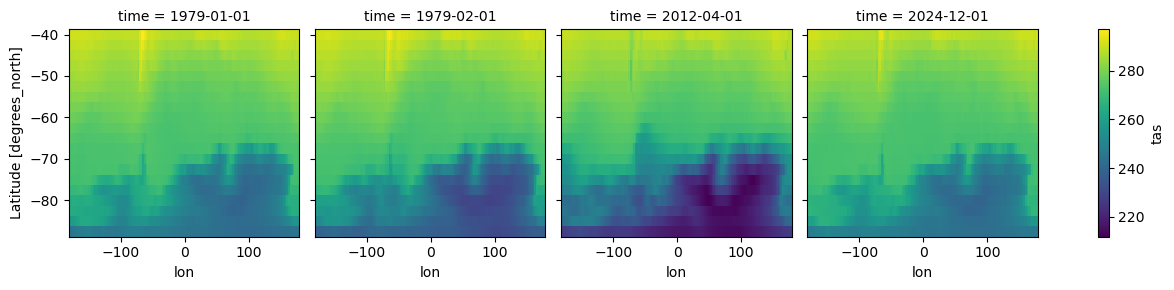

In [21]:
era5_monthly_da.isel(time=[0, 1, 399, -1]).plot(col='time')

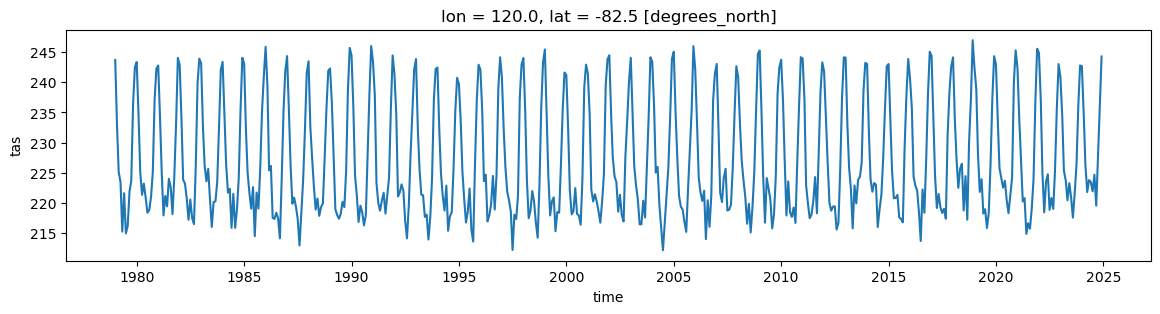

In [18]:
era5_monthly_da.sel(**config.POINT).plot(figsize=(14, 3));

## 3. Monthly to Seasonal Means

### Open the monthly data

Run **one** of the next two sections. Both leave the same variables: `lesfmip_tree`, monthly LESFMIP as a DataTree laid out `/<model>/<experiment>`, and `era5_monthly_da`, both in the units of the raw files.

#### Sample data

The 3×3 block of grid cells around `config.POINT` in `tests/data`: two models, every experiment.

In [225]:
#(t): The sample's files: <model>_<experiment>_sample.nc, monthly tas in K on (member, time, lat, lon)
sample_paths = sorted(SAMPLE_DIR.glob('*_*_sample.nc'))
sample_paths

[PosixPath('../tests/data/CanESM5_hist-GHG_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-aer_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-lu_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-nat_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-sol_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-volc_sample.nc'),
 PosixPath('../tests/data/CanESM5_historical_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-GHG_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-aer_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-lu_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-nat_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-sol_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-volc_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_historical_sample.nc')]

In [226]:
#(t): The model and experiment of each file, from its name
sample_names = [path.stem.removesuffix('_sample').rsplit('_', 1) for path in sample_paths]

In [ ]:
#(t): Each file of config.MAIN_EXPERIMENTS opened, as a DataTree /<model>/<experiment>
lesfmip_tree = xr.DataTree.from_dict({f'{model}/{experiment}': xr.open_dataset(path).load()
                                      for path, (model, experiment) in zip(sample_paths, sample_names)
                                      if experiment in config.MAIN_EXPERIMENTS})

In [ ]:
#(t): ERA5's sample file: monthly tas in K from 1979, on (time, lat, lon)
era5_sample_path = SAMPLE_DIR / 'era5_sample.nc'
era5_monthly_da = xr.open_dataarray(era5_sample_path).load()

#### Full data

The monthly stores section 1 made, in `MONTHLY_DIR`: the `config.N_MODELS` models with stores for the most experiments.

In [233]:
config.MAIN_MODELS

['CanESM5',
 'GISS-E2-1-G',
 'HadGEM3-GC31-LL',
 'MIROC6',
 'MPI-ESM1-2-LR',
 'NorESM2-LM']

In [234]:
#(t): The monthly stores of VARIABLE.name (the config.GROUP ones): <model>_<variable>_<experiment>_<group>_monthly.zarr
monthly_store_paths = sorted(MONTHLY_DIR.glob(f'*_{VARIABLE.name}_*_{config.GROUP}_monthly.zarr'))
monthly_store_paths = [mp for mp in monthly_store_paths if str(mp).split('/')[-1].split('_')[0] in config.MAIN_MODELS]
monthly_store_paths

[PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-GHG_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-aer_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-lu_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-nat_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-sol_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-totalO3_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-volc_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_historical_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/GISS-E2-1-G_tas_hist-GHG_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/GISS-E2-1-G_tas_hist-aer_interp_mo

In [235]:
#(t): The model and experiment of each store, from its name
monthly_stores_df = pd.DataFrame([path.name.removesuffix('_monthly.zarr').rsplit('_', 3) for path in monthly_store_paths],
                                 columns=['model', 'variable', 'experiment', 'group']).assign(path=monthly_store_paths)

In [236]:
#(t): Which models have a store for which experiment
stores_df = pd.crosstab(monthly_stores_df['model'], monthly_stores_df['experiment'])

In [237]:
#(t): The number of config.MAIN_EXPERIMENTS each model has, the most first
experiments_per_model = stores_df.reindex(columns=config.MAIN_EXPERIMENTS, fill_value=0).sum(axis=1)
experiments_per_model = experiments_per_model.sort_values(ascending=False, kind='stable')

In [238]:
#(t): The config.N_MODELS models with the most
models = list(experiments_per_model.index[:config.N_MODELS])
models

['CanESM5',
 'GISS-E2-1-G',
 'HadGEM3-GC31-LL',
 'MIROC6',
 'MPI-ESM1-2-LR',
 'NorESM2-LM']

In [239]:
#(t): Their stores of config.MAIN_EXPERIMENTS
open_stores_df = monthly_stores_df[monthly_stores_df['model'].isin(models)
                                   & monthly_stores_df['experiment'].isin(config.MAIN_EXPERIMENTS)]

In [240]:
#(t): Each opened (lazily), as a DataTree /<model>/<experiment>
lesfmip_tree = xr.DataTree.from_dict({f'{row.model}/{row.experiment}': xr.open_zarr(row.path, consolidated=True)
                                      for row in open_stores_df.itertuples()})

In [241]:
#(t): ERA5's monthly means (section 2)
era5_monthly_path = SCRATCH_DIR / 'monthly' / f'era5_{VARIABLE.name}.zarr'
era5_monthly_da = xr.open_zarr(era5_monthly_path)[VARIABLE.name]

### What is there

How many members each model ran for each experiment. A model's members differ only in their initial conditions, so the spread across them is the model's internal variability, and the more members, the better the forced response and the variability are pinned down.

In [242]:
#(t): Members per model (rows) and experiment (columns)
member_counts_df = pd.Series({(node.parent.name, node.name): node.sizes['member'] for node in lesfmip_tree.leaves})
member_counts_df = member_counts_df.unstack()[[e for e in config.MAIN_EXPERIMENTS if e in member_counts_df.index.levels[1]]]

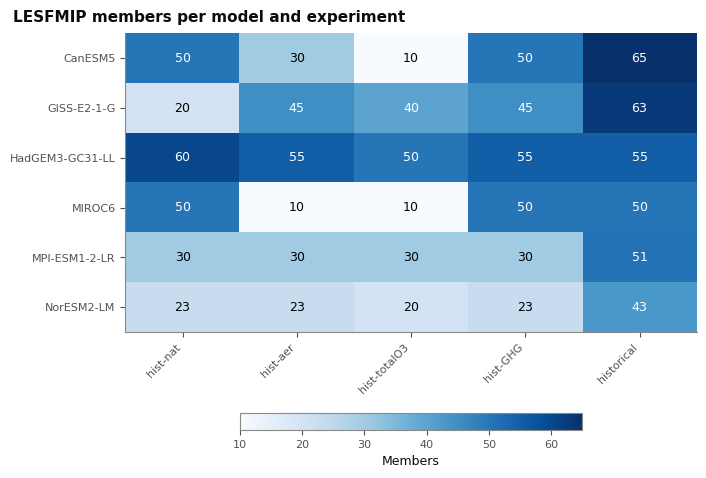

In [243]:
#(t): LESFMIP members: each model (rows) and experiment (columns), grey where there are none
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, n_colorbars=1,
                                                  panel_width=0.9 * member_counts_df.shape[1] + 0.5,
                                                  panel_height=0.4 * member_counts_df.shape[0] + 0.3, left_margin=1.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
counts_image = methods.plot_member_counts(member_counts_df, ax=axes[0, 0])
fig.colorbar(counts_image, ax=axes, location='bottom', shrink=0.6, label='Members')
fig.suptitle('LESFMIP members per model and experiment', x=0.01, ha='left');

In [244]:
#(t): Every node's dimensions, size in memory and chunking
pd.DataFrame.from_dict({node.path: datatree.coord_info(node.to_dataset()) for node in lesfmip_tree.leaves},
                       orient='index')

size                 chunk                 \
                              member  time lat  lon member  time lat  lon   
/CanESM5/hist-GHG                 50  2052  20  144      5  2052  10  144   
/CanESM5/hist-aer                 30  2052  20  144      5  2052  10  144   
/CanESM5/hist-nat                 50  2052  20  144      5  2052  10  144   
/CanESM5/hist-totalO3             10  2052  20  144      5  2052  10  144   
/CanESM5/historical               65  1980  20  144      5  1980  10  144   
/GISS-E2-1-G/hist-GHG             45  1980  20  144      5  1980  10  144   
/GISS-E2-1-G/hist-aer             45  1980  20  144      5  1980  10  144   
/GISS-E2-1-G/hist-nat             20  1980  20  144      5  1980  10  144   
/GISS-E2-1-G/hist-totalO3         40  1980  20  144      5  1980  10  144   
/GISS-E2-1-G/historical           63  1980  20  144      5  1980  10  144   
/HadGEM3-GC31-LL/hist-GHG         55  2052  20  144      5  2052  10  144   
/HadGEM3-GC31-LL/hist-aer         55  2052  20  144      5  2052  10  144   
/HadGEM3-GC31-LL/hist-nat         60  2052  20  144      5  2052  10  144   
/HadGEM3-GC31-LL/hist-totalO3     50  2052  20  144      5  2052  10  144   
/HadGEM3-GC31-LL/historical       55  1980  20  144      5  1980  10  144   
/MIROC6/hist-GHG                  50  2052  20  144      5  2052  10  144   
/MIROC6/hist-aer                  10  2052  20  144      5  2052  10  144   
/MIROC6/hist-nat                  50  2052  20  144      5  2052  10  144   
/MIROC6/hist-totalO3              10  2052  20  144      5  2052  10  144   
/MIROC6/historical                50  1980  20  144      5  1980  10  144   
/MPI-ESM1-2-LR/hist-GHG           30  1980  20  144      5  1980  10  144   
/MPI-ESM1-2-LR/hist-aer           30  1980  20  144      5  1980  10  144   
/MPI-ESM1-2-LR/hist-nat           30  1980  20  144      5  1980  10  144   
/MPI-ESM1-2-LR/hist-totalO3       30  1980  20  144      5  1980  10  144   
/MPI-ESM1-2-LR/historical         51  1980  20  144      5  1980  10  144   
/NorESM2-LM/hist-GHG              23  2052  20  144      5  2052  10  144   
/NorESM2-LM/hist-aer              23  2052  20  144      5  2052  10  144   
/NorESM2-LM/hist-nat              23  2052  20  144      5  2052  10  144   
/NorESM2-LM/hist-totalO3          20  2052  20  144      5  2052  10  144   
/NorESM2-LM/historical            43  1980  20  144      5  1980  10  144   

                              memory                       
                              mbytes chunk_mbytes nchunks  
/CanESM5/hist-GHG               1127         56.4      20  
/CanESM5/hist-aer                676         56.4      12  
/CanESM5/hist-nat               1127         56.4      20  
/CanESM5/hist-totalO3            225         56.4       4  
/CanESM5/historical             2827        108.8      26  
/GISS-E2-1-G/hist-GHG            978         54.4      18  
/GISS-E2-1-G/hist-aer            978         54.4      18  
/GISS-E2-1-G/hist-nat            435         54.4       8  
/GISS-E2-1-G/hist-totalO3        870         54.4      16  
/GISS-E2-1-G/historical         1370         54.4      26  
/HadGEM3-GC31-LL/hist-GHG       1239         56.4      22  
/HadGEM3-GC31-LL/hist-aer       1239         56.4      22  
/HadGEM3-GC31-LL/hist-nat       1352         56.4      24  
/HadGEM3-GC31-LL/hist-totalO3   1127         56.4      20  
/HadGEM3-GC31-LL/historical     1196         54.4      22  
/MIROC6/hist-GHG                1127         56.4      20  
/MIROC6/hist-aer                 225         56.4       4  
/MIROC6/hist-nat                1127         56.4      20  
/MIROC6/hist-totalO3             225         56.4       4  
/MIROC6/historical              1087         54.4      20  
/MPI-ESM1-2-LR/hist-GHG          652         54.4      12  
/MPI-ESM1-2-LR/hist-aer          652         54.4      12  
/MPI-ESM1-2-LR/hist-nat          652         54.4      12  
/MPI-ESM1-2-LR/hist-totalO3      652         54.4      12  
/MPI-ES

In [245]:
#(t): Two months of one member, to see the domain (everything south of 40°S)
months_ds = lesfmip_tree[config.PLOT_SEL['model']][config.PLOT_SEL['experiment']].to_dataset().isel(member=0, time=[0, 6])

In [246]:
#(t): ... in analysis units
months_da = pp.to_analysis_units(months_ds, VARIABLE.name)[VARIABLE.name].load()

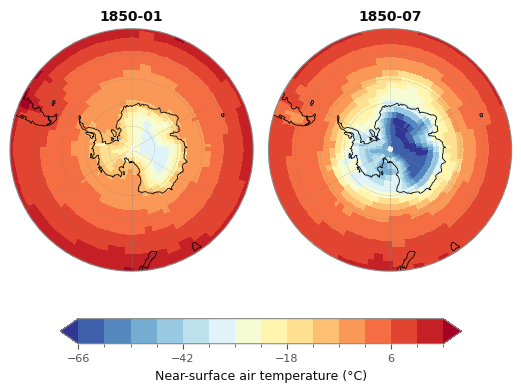

In [247]:
#(t): Quick look: the two months on maps of Antarctica, on one colour bar from the field's 2nd to its 98th percentile,
#(t): in about 14 round steps (MaxNLocator), with every fourth labelled
month_times_arr = months_da['time'].values
levels = MaxNLocator(14).tick_values(float(months_da.quantile(0.02)), float(months_da.quantile(0.98)))
fig = plt.figure(figsize=antarctica.map_figure_size(n_rows=1, n_cols=len(month_times_arr), n_colorbar_rows=1),
                 layout='constrained')
axes = antarctica.map_axes(fig, n_rows=1, n_cols=len(month_times_arr))
cax = antarctica.colorbar_axis_below(axes)

antarctica.heatmaps_of_antarctica(months_da, None, 'time', axes=axes, cax=cax, levels=levels, cmap='RdYlBu_r',
                                  ticks=levels[::4], label=VARIABLE.label)
antarctica.label_columns(axes, [str(month)[:7] for month in month_times_arr]);

### How a seasonal mean is made

Each season is the mean of its three monthly means (each month counts equally, whatever its length):

$$
\bar{x}_{\mathrm{DJF},\,y} = \tfrac{1}{3}\left(x_{\mathrm{Dec}\,y} + x_{\mathrm{Jan}\,y+1} + x_{\mathrm{Feb}\,y+1}\right),
\qquad
\bar{x}_{\mathrm{MAM},\,y} = \tfrac{1}{3}\left(x_{\mathrm{Mar}\,y} + x_{\mathrm{Apr}\,y} + x_{\mathrm{May}\,y}\right), \ \ldots
$$

so DJF is labelled by the year of its December, and a "year" runs from March to the next February. Seasons with fewer than three months are dropped (the January–February stub at the start of a record), and so is any year without all four seasons. Every experiment is first cut at the end of 2014, where historical ends, so the record ends with DJF 2013 and "the final 21 years" are the same years in every experiment. The time axis is then split into `year` × `season` (`pp.split_time`), so that a rolling window moves through the years of one season.

The figure: one member at `config.POINT`, monthly means (grey) and the seasonal means made from them.

In [248]:
#(t): One member at the example point, monthly, on time
point_monthly_ds = lesfmip_tree[config.PLOT_SEL['model']][config.PLOT_SEL['experiment']].to_dataset().sel(**config.POINT)

In [249]:
#(t): ... in analysis units, the first member
point_monthly_da = pp.to_analysis_units(point_monthly_ds, VARIABLE.name)[VARIABLE.name].isel(member=0).load()

In [250]:
#(t): Its seasonal means on (year, season), cut where historical ends (config.LAST_MONTH)
point_seasonal_da = pp.seasonal_means(point_monthly_da.sel(time=slice(None, config.LAST_MONTH)))
point_seasonal_da

<xarray.DataArray 'tas' (year: 164, season: 4)> Size: 3kB
-33.05 -59.62 -51.54 -49.37 -33.0 -59.67 ... -47.03 -29.38 -58.4 -53.74 -48.39
Coordinates:
  * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
  * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
    lon      float64 8B 120.0
    lat      float64 8B -82.5
    member   <U9 36B 'r10i1p1f1'

In [251]:
#(t): Check by hand: DJF 1990 is the mean of December 1990, January 1991 and February 1991: the three months, their
#(t): mean, and DJF 1990 (the last two the same)
djf_months_arr = point_monthly_da.sel(time=slice('1990-12', '1991-02')).values
djf_months_arr.round(3), djf_months_arr.mean().round(3), point_seasonal_da.sel(year=1990, season='DJF').values.round(3)

(array([-28.574, -27.196, -39.028], dtype=float32),
 np.float32(-31.599),
 np.float32(-31.599))

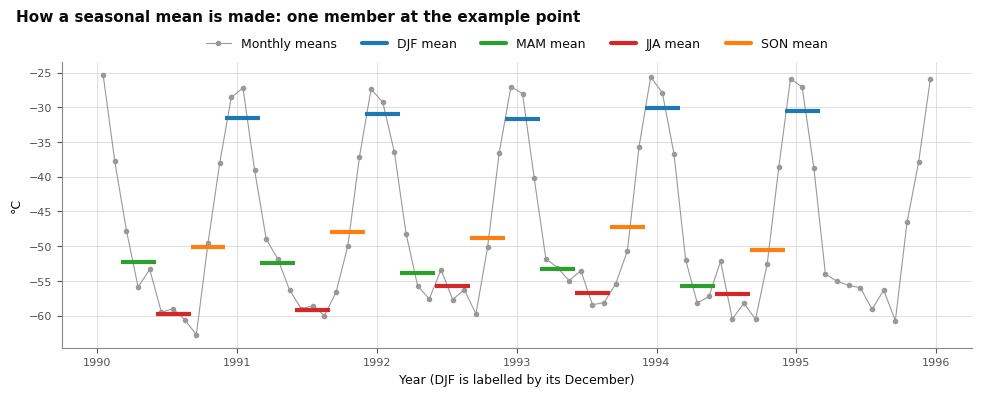

In [252]:
#(t): One member at the example point, 1990-1995: the monthly means (grey) and the seasonal means made from them (a bar
#(t): across each season's months)
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, panel_width=8.8, panel_height=2.6),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
methods.plot_seasonal_means(point_monthly_da, point_seasonal_da, slice(1990, 1995), ax=axes[0, 0])
axes[0, 0].set_xlabel('Year (DJF is labelled by its December)')
axes[0, 0].set_ylabel(VARIABLE.units)
fig.suptitle('How a seasonal mean is made: one member at the example point', x=0.01, ha='left');

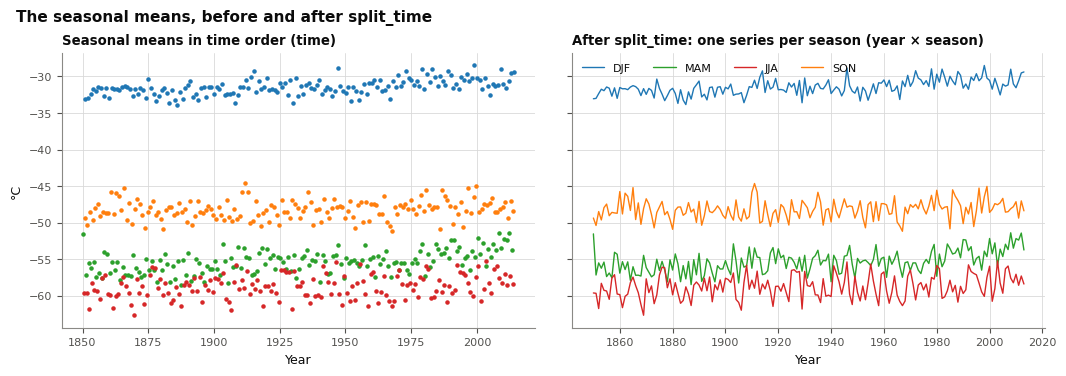

In [253]:
#(t): The same seasonal means, before (in time order) and after splitting time into year x season (one series per
#(t): season), on one y axis
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=2, n_legends=0, panel_width=4.6, panel_height=2.4),
                 layout='constrained')
axes = fig.add_gridspec(1, 2).subplots(sharey=True, squeeze=False)
methods.plot_seasons_in_time(point_seasonal_da, ax=axes[0, 0])
methods.plot_seasons_split(point_seasonal_da, ax=axes[0, 1])
axes[0, 0].set_title('Seasonal means in time order (time)', loc='left')
axes[0, 1].set_title('After split_time: one series per season (year × season)', loc='left')
axes[0, 0].set_ylabel(VARIABLE.units)
for ax in axes[0]:
    ax.set_xlabel('Year')
fig.suptitle('The seasonal means, before and after split_time', x=0.01, ha='left');

### All of it

`pp.seasonal_tree` runs these steps on every model and experiment, and `pp.seasonal_era5` on ERA5, which it also puts on the LESFMIP grid (`pp.match_grid`) and starts in 1979 (`config.ERA5_START_YEAR`), the start of the satellite era. Both are lazy: nothing is computed until the result is saved or loaded.

In [254]:
#(t): Every model and experiment's seasonal means (lazily)
lesfmip_season_tree = pp.seasonal_tree(lesfmip_tree, VARIABLE.name)
lesfmip_season_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:  (member: 30, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * member   (member) object 240B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 227MB dask.array<chunksize=(30, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:  (member: 50, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 378MB dask.array<chunksize=(50, 4, 144, 164, 4), meta=np.ndarray>
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:  (member: 10, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * member   (member) object 80B 'r10i1p1f1' 'r1i1p1f1' ... 'r9i1p1f1'
│   │         * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│   │         * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │       Data variables:
│   │           tas      (member, lat, lon, year, season) float32 76MB dask.array<chunksize=(10, 4, 144, 164, 4), meta=np.ndarray>
│   └── Group: /CanESM5/historical
│           Dimensions:  (member: 65, lat: 20, lon: 144, year: 164, season: 4)
│           Coordinates:
│             * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│             * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│             * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
│             * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
│           Data variables:
│               tas      (member, lat, lon, year, season) float32 491MB dask.array<chunksize=(65, 4, 144, 164, 4), meta=np.ndarray>
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (member: 45, lat: 20, lon: 144, year: 164, season: 4)
│   │       Coordinates:
│   │         * year     (year) int64 1kB 1850 1851 1852 1853 1854 ... 2010 2011 2012 2013
│   │         * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
│   │         * lo

In [255]:
#(t): ERA5's, on the LESFMIP grid, from config.ERA5_START_YEAR (lazily)
era5_seasonal_da = pp.seasonal_era5(era5_monthly_da, VARIABLE.name, like=lesfmip_season_tree)
era5_seasonal_da

<xarray.DataArray 'tas' (lat: 20, lon: 144, year: 45, season: 4)> Size: 2MB
dask.array<chunksize=(10, 72, 15, 4), meta=np.ndarray>
Coordinates:
  * year     (year) int64 360B 1979 1980 1981 1982 1983 ... 2020 2021 2022 2023
  * season   (season) <U3 48B 'DJF' 'JJA' 'MAM' 'SON'
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5

### Save

Writing computes everything, in parallel on the cluster. The other notebooks then open these two stores in seconds.

In [256]:
%%time
#(t): The seasonal LESFMIP means, a DataTree /<model>/<experiment>
lesfmip_season_path = SCRATCH_DIR / 'seasonal' / f'lesfmip_{VARIABLE.name}.zarr'
lesfmip_season_tree.to_zarr(lesfmip_season_path, mode='w')
lesfmip_season_path

CPU times: user 1.42 s, sys: 1.03 s, total: 2.45 s
Wall time: 1min 41s


PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr')

In [257]:
%%time
#(t): ERA5's seasonal means
era5_seasonal_path = SCRATCH_DIR / 'seasonal' / f'era5_{VARIABLE.name}.zarr'
era5_seasonal_da.to_dataset(name=VARIABLE.name).to_zarr(era5_seasonal_path, mode='w')
era5_seasonal_path

CPU times: user 29.1 ms, sys: 22.9 ms, total: 51.9 ms
Wall time: 1.45 s


PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/era5_tas.zarr')

In [258]:
#(t): Reopened from what was saved, for the checks below
lesfmip_season_tree = xr.open_datatree(lesfmip_season_path, engine='zarr', chunks={})

In [259]:
era5_seasonal_da = xr.open_zarr(era5_seasonal_path)[VARIABLE.name]

### Checks

The seasonal means at the example point: the members of one model (grey) and ERA5 (black) over the years they share. ERA5 should sit among the members; a constant offset would be a mean-state bias of the model, which the ERA5 notebook tests properly.

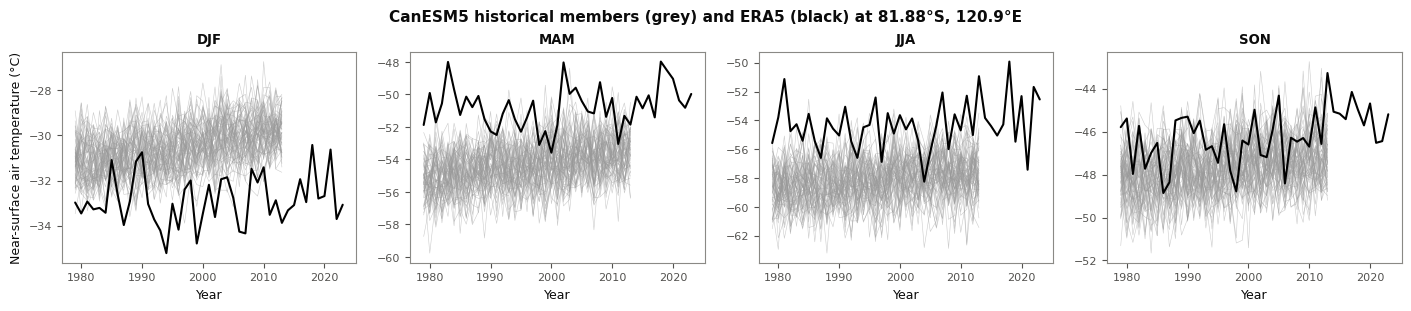

In [260]:
#(t): ERA5 among one model's historical members at the example point, every season
point_members_da = lesfmip_season_tree[config.PLOT_SEL['model']][config.PLOT_SEL['experiment']][VARIABLE.name].sel(**config.POINT)
fig, axes = plt.subplots(1, 4, figsize=(14, 3), sharex=True, layout='constrained')
for ax, season in zip(axes, ['DJF', 'MAM', 'JJA', 'SON']):
    members_da = point_members_da.sel(season=season, year=slice(config.ERA5_START_YEAR, None))
    ax.plot(members_da.year, members_da.transpose('year', 'member'), color='0.6', lw=0.4, alpha=0.5)
    ax.plot(era5_seasonal_da.year, era5_seasonal_da.sel(**config.POINT).sel(season=season), color='k', lw=1.5)
    ax.set_title(season)
    ax.set_xlabel('Year')
axes[0].set_ylabel(VARIABLE.label)
fig.suptitle(f"{config.PLOT_SEL['model']} {config.PLOT_SEL['experiment']} members (grey) and ERA5 (black) "
             f"at {formatting.format_latlon(config.POINT)}");

## 4. Test Sample

The 3×3 block of grid cells around `config.POINT`, from two models with every experiment and from ERA5, saved to `tests/data`. The tests and the sample sections of every notebook use it. It is temperature only, so only re-run this for `tas`.

In [261]:
#(t): Two models' monthly stores of every experiment, in MONTHLY_DIR
sample_store_paths = (sorted(MONTHLY_DIR.glob(f'CanESM5_{VARIABLE.name}_*_{config.GROUP}_monthly.zarr'))
                      + sorted(MONTHLY_DIR.glob(f'HadGEM3-GC31-LL_{VARIABLE.name}_*_{config.GROUP}_monthly.zarr')))
sample_store_paths

[PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-GHG_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-aer_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-lu_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-nat_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-sol_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-totalO3_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-volc_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_historical_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/HadGEM3-GC31-LL_tas_hist-GHG_interp_monthly.zarr'),
 PosixPath('/work/scratch-pw4/aborow/LESFMIP/monthly_v2/HadGEM3-GC31-LL_tas_hist-aer_i

In [262]:
#(t): Each opened (lazily), as a DataTree /<model>/<experiment>, the model and experiment from the store's name
sample_tree = xr.DataTree.from_dict({
    '/'.join(path.name.removesuffix('_monthly.zarr').rsplit('_', 3)[0:3:2]): xr.open_zarr(path)
    for path in sample_store_paths
})

GroupNotFoundError: No group found in store '/work/scratch-pw4/aborow/LESFMIP/monthly_v2/CanESM5_tas_hist-lu_interp_monthly.zarr' at path ''

In [ ]:
#(t): ERA5's monthly means (section 2)
era5_monthly_da = xr.open_zarr(SCRATCH_DIR / 'monthly' / f'era5_{VARIABLE.name}.zarr')[VARIABLE.name]

In [ ]:
#(t): The 3×3 block of cells around config.POINT: the nearest row and column of the grid, and one either side
centre_lat_index = era5_monthly_da.indexes['lat'].get_indexer([config.POINT['lat']], method='nearest')[0]
centre_lon_index = era5_monthly_da.indexes['lon'].get_indexer([config.POINT['lon']], method='nearest')[0]
sample_cells = dict(lat=era5_monthly_da['lat'].values[centre_lat_index - 1:centre_lat_index + 2],
                    lon=era5_monthly_da['lon'].values[centre_lon_index - 1:centre_lon_index + 2])
sample_cells

In [263]:
%%time
#(t): Each model and experiment saved as <model>_<experiment>_sample.nc in SAMPLE_DIR. tolerance makes a grid mismatch
#(t): fail loudly instead of picking other cells; drop_encoding: the zarr stores' settings are not netCDF's
for node in sample_tree.leaves:
    sample_path = SAMPLE_DIR / f'{node.parent.name}_{node.name}_sample.nc'
    node_sample_ds = node.to_dataset().sel(sample_cells, method='nearest', tolerance=0.01).drop_encoding().load()
    node_sample_ds.to_netcdf(sample_path)
    logger.info(f'saved {sample_path}')

CPU times: user 9 μs, sys: 2 μs, total: 11 μs
Wall time: 17.2 μs


NameError: name 'sample_tree' is not defined

In [ ]:
#(t): ERA5's block, as era5_sample.nc
era5_sample_path = SAMPLE_DIR / 'era5_sample.nc'
era5_monthly_da.sel(sample_cells, method='nearest', tolerance=0.01).drop_encoding().load().to_netcdf(era5_sample_path)
era5_sample_path

In [ ]:
#(t): What is in SAMPLE_DIR now, and each file's size (MB)
{path.name: round(path.stat().st_size / 1e6, 1) for path in sorted(SAMPLE_DIR.glob('*_sample.nc'))}

## 5. Sea Ice (Notebook calc_04)

The sea ice is not in the LEADER-EPESC folders, so it no longer comes through here. Notebook calc_04 takes it from CEDA's copy of the CMIP6 archive, puts it on the 2.5° grid, checks it against ERA5, and saves what notebooks plot_03 and plot_06 read (`results/siconc/<run>/extent.zarr` and `climatology.zarr`).

## 6. SAM Index

The Southern Annular Mode index that sorts the seasons into SAM phases (notebook calc_02a, *SAM Phases*) is not made here from sea-level pressure: LEADER-EPESC working group 1 has already made a monthly index for every LESFMIP member, the files `archive/draft_current_DAILY.ipynb` opened. It is the zonal-mean index of Gong & Wang (1999), the difference between standardised zonal-mean pressure at 40°S and 65°S. This section turns it into seasonal means, as section 3 does every other variable, and saves them as `seasonal/lesfmip_sam.zarr`. Run it once, whatever `VARIABLE` is.

**Where the files are.** `SAM_RAW_DIR`, one file per member: `/<experiment>/<model>/SAM_zonal_mon_<experiment>_<model>_<member>_interp.nc`, with `SAM` on (time_mm, level). The code is in `extant/sam.py`.

**Which level?** The draft took `level=3`, and a later version of its reader `level=0`, which it called the surface. The cells below show one file's levels: set `SAM_LEVEL` to the position of the one wanted.

In [ ]:
#(t): Where the index files are
SAM_RAW_DIR

In [ ]:
#(t): The models analysed: those in the seasonal store of VARIABLE.name (section 3)
sam_models = list(xr.open_datatree(SCRATCH_DIR / 'seasonal' / f'lesfmip_{VARIABLE.name}.zarr', engine='zarr').children)
sam_models

In [ ]:
#(t): Each model's and experiment's member files: /<experiment>/<model>/*.nc in SAM_RAW_DIR
sam_index_paths = {(model, experiment): sorted((SAM_RAW_DIR / experiment / model).glob('*.nc'))
                   for model in sam_models for experiment in config.MAIN_EXPERIMENTS}

In [ ]:
#(t): How many member files each model and experiment has
sam_files_df = pd.Series({key: len(index_paths) for key, index_paths in sam_index_paths.items()}).unstack()
sam_files_df

In [ ]:
#(t): One file as it is, to see its variables and its levels
sam_example_path = sam_index_paths[config.PLOT_SEL['model'], 'hist-nat'][0]
sam_example_path

In [ ]:
sam_example_ds = xr.open_dataset(sam_example_path)
sam_example_ds

In [ ]:
#(t): The levels to choose from
sam_example_ds['level']

In [ ]:
#(t): Quick look: the index of this member at every level
sam_example_ds['SAM'].plot.line(x='time_mm', hue='level', add_legend=True, figsize=(14, 4));

In [ ]:
#(t): The position along `level` of the index used
SAM_LEVEL = 0

In [ ]:
%%time
#(t): Every model and experiment with files, opened lazily as a DataTree /<model>/<experiment>, monthly, on (member, time)
sam_monthly_tree = xr.DataTree.from_dict({
    f'{model}/{experiment}': sam.open_index(index_paths, level=SAM_LEVEL)
    for (model, experiment), index_paths in sam_index_paths.items() if index_paths
})

In [ ]:
#(t): Cut where historical ends, as every other variable is (config.LAST_MONTH)
sam_cut_tree = sam_monthly_tree.sel(time=slice(None, config.LAST_MONTH))

In [ ]:
#(t): Seasonal means of complete seasons in whole years (as in section 3)
sam_seasonal_tree = sam_cut_tree.map_over_datasets(pp.seasonal_mean)

In [ ]:
#(t): time split into year and season
sam_season_tree = sam_seasonal_tree.map_over_datasets(datatree.skip_empty(pp.split_time),
                                                      kwargs=dict(parts=('year', 'season'), dim='time'))

In [ ]:
%%time
sam_season_tree = sam_season_tree.compute()
sam_season_tree

In [ ]:
#(t): Saved for notebook calc_02a
sam_season_path = SCRATCH_DIR / 'seasonal' / 'lesfmip_sam.zarr'
sam_season_tree.to_zarr(sam_season_path, mode='w')
sam_season_path

In [ ]:
#(t): Check: every model's DJF index, each experiment's ensemble mean (the ozone hole should show in historical and
#(t): hist-totalO3 from about 1980)
sam_check_ds = datatree.tree_to_dataset(sam_season_tree.mean('member'), dims=['model', 'experiment'])
sam_check_ds['sam'].sel(season='DJF').plot(x='year', hue='experiment', col='model', col_wrap=3);

## Moving Outputs to the Group Workspace

Once a store is written and checked, move it from scratch to the group workspace, keeping the same layout, e.g.

```bash
mkdir -p /gws/ssde/j25b/leader_epesc/aborow/ExtAnt/seasonal
mv /work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr /gws/ssde/j25b/leader_epesc/aborow/ExtAnt/seasonal/
```

or everything at once with `rsync -a --remove-source-files /work/scratch-pw4/aborow/ExtAnt/ /gws/ssde/j25b/leader_epesc/aborow/ExtAnt/`. The notebooks read from scratch (`SCRATCH_DIR` in each one's Settings), so after a move, set `SCRATCH_DIR` to the group workspace folder in the notebooks that read the store.